In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries install successfully!!!")

Libraries install successfully!!!


In [2]:
df = pd.read_csv(r"C:\Users\Dell\Desktop\Bank_Customer_Churn_Analysis\Dataset\Churn_Modelling.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
print("Dataset Shape:",df.shape)

print("\nColumns Names:")
print(df.columns.tolist())

print("Dataset Information:")
df.info()


Dataset Shape: (10000, 14)

Columns Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  Estimate

In [8]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicated Records:")
print(df.duplicated().sum())

print("\nChurn Distribution")
print(df["Exited"].value_counts())

print("Overall Churn Rate:")
print(round(df["Exited"].mean() * 100, 2), "%")

Missing Values:
0
Duplicated Records:
0

Churn Distribution
Exited
0    7963
1    2037
Name: count, dtype: int64
Overall Churn Rate:
20.37 %


In [9]:

bins = [0, 25, 35, 45, 55, 100]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

age_churn = df.groupby(
    "AgeGroup", observed=False
)["Exited"].mean() * 100

print(age_churn.round(2))


AgeGroup
18-25     7.53
26-35     8.50
36-45    19.62
46-55    50.57
56+      36.75
Name: Exited, dtype: float64


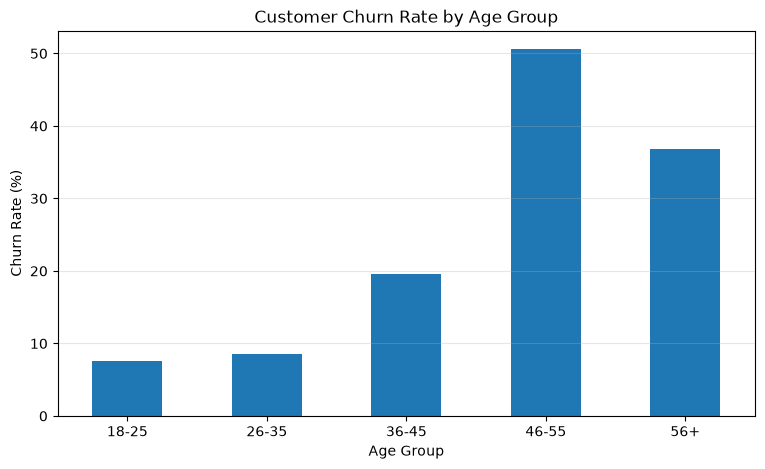

In [10]:

plt.figure(figsize=(9, 5))

age_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [11]:

product_count = df["NumOfProducts"].value_counts().sort_index()

print("Customers by Product Holding:")
print(product_count)


Customers by Product Holding:
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64


In [12]:

product_churn = df.groupby(
    "NumOfProducts"
)["Exited"].mean() * 100

print("Churn Rate by Product Holding:")
print(product_churn.round(2))


Churn Rate by Product Holding:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


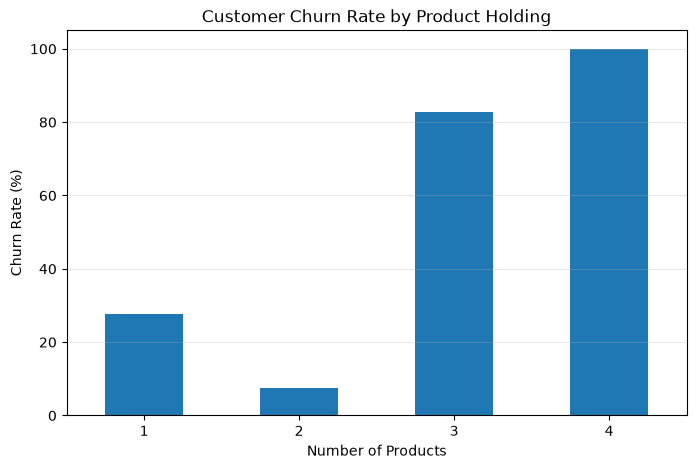

In [13]:

plt.figure(figsize=(8, 5))

product_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Product Holding")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [14]:

geo_count = df["Geography"].value_counts()

print("Customers by Geography:")
print(geo_count)


Customers by Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64


In [15]:

geo_churn = df.groupby("Geography")["Exited"].mean() * 100

print("Churn Rate by Geography:")
print(geo_churn.round(2))


Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


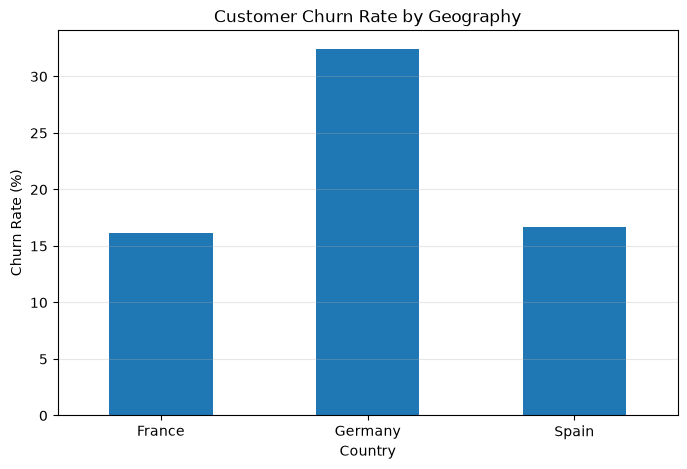

In [16]:

plt.figure(figsize=(8, 5))

geo_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [17]:

bins = [-1, 2, 5, 8, 10]
labels = ["0-2 Years", "3-5 Years", "6-8 Years", "9-10 Years"]

df["TenureGroup"] = pd.cut(
    df["Tenure"],
    bins=bins,
    labels=labels
)

print(df[["Tenure", "TenureGroup", "Exited"]].head(10))


   Tenure TenureGroup  Exited
0       2   0-2 Years       1
1       1   0-2 Years       0
2       8   6-8 Years       1
3       1   0-2 Years       0
4       2   0-2 Years       0
5       8   6-8 Years       1
6       7   6-8 Years       0
7       4   3-5 Years       1
8       4   3-5 Years       0
9       2   0-2 Years       0


In [18]:

tenure_churn = df.groupby(
    "TenureGroup", observed=False
)["Exited"].mean() * 100

print("Churn Rate by Tenure:")
print(tenure_churn.round(2))


Churn Rate by Tenure:
TenureGroup
0-2 Years     21.15
3-5 Years     20.76
6-8 Years     18.87
9-10 Years    21.30
Name: Exited, dtype: float64


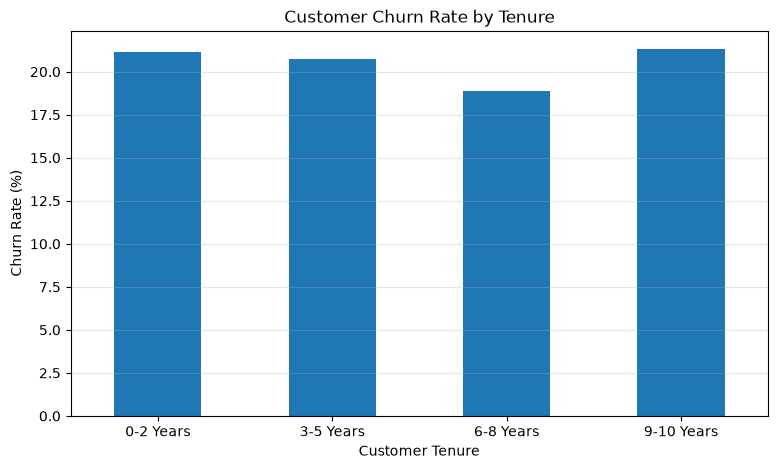

In [19]:

plt.figure(figsize=(9, 5))

tenure_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [20]:

output_path = r"C:\Users\Dell\Desktop\Bank_Customer_Churn_Analysis\Dataset\Bank_Churn_Analysis.csv"

df.to_csv(output_path, index=False)

print("Final dataset exported successfully!")


Final dataset exported successfully!
